Grand Cam 

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision import models, transforms

from PIL import Image

# Find the project root directory
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

# Define important project directories
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODEL_DIR = PROJECT_ROOT / "results" / "models"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
EXPLANATION_DIR = PROJECT_ROOT / "results" / "explanations" / "gradcam"

# Create output directory
EXPLANATION_DIR.mkdir(parents=True, exist_ok=True)

# Select CPU or GPU automatically
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", PROJECT_ROOT)
print("Device:", device)
print("Model directory exists:", MODEL_DIR.exists())
print("Processed data directory exists:", PROCESSED_DIR.exists())

Project root: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L
Device: cpu
Model directory exists: True
Processed data directory exists: True


Load the fold information and predictions

In [2]:
# Load the five-fold split information
folds_df = pd.read_csv(PROCESSED_DIR / "folds.csv")

# Load the combined predictions from Notebook 03
predictions_df = pd.read_csv(
    METRICS_DIR / "combined_test_predictions.csv"
)

# Display the first five rows
print("Fold information:")
display(folds_df.head())

print("\nCombined predictions:")
display(predictions_df.head())

# Check dataset sizes
print("\nTotal images in fold information:", len(folds_df))
print("Total predictions:", len(predictions_df))

# Check images assigned to each test fold
print("\nImages per test fold:")
print(folds_df["test_fold"].value_counts().sort_index())


# Compare the fold information with the prediction information
fold_check = folds_df[
    ["image_filename", "test_fold"]
].merge(
    predictions_df[["image_filename", "fold"]],
    on="image_filename",
    how="inner"
)

# Check whether both fold numbers match
fold_check["fold_matches"] = (
    fold_check["test_fold"] == fold_check["fold"]
)

print("Total matched images:", len(fold_check))
print("Matching fold assignments:", fold_check["fold_matches"].sum())
print("Mismatched fold assignments:", (~fold_check["fold_matches"]).sum())

# Display any mismatches
display(fold_check[fold_check["fold_matches"] == False])

Fold information:


,image_filename,Texture,group_id,test_fold
0,W001.jpg,twill,10,2
1,W002.jpg,twill,10,2
2,W003.jpg,twill,10,2
3,W004.jpg,twill,10,2
4,W005.jpg,twill,10,2



Combined predictions:


,image_filename,actual_class,predicted_class,confidence,fold,correct
0,W006.jpg,twill,twill,0.970566,1,True
1,W007.jpg,twill,twill,0.698218,1,True
2,W008.jpg,twill,twill,0.977882,1,True
3,W009.jpg,twill,twill,0.992629,1,True
4,W010.jpg,twill,twill,0.995661,1,True



Total images in fold information: 130
Total predictions: 130

Images per test fold:
test_fold
1    27
2    23
3    30
4    26
5    24
Name: count, dtype: int64
Total matched images: 130
Matching fold assignments: 130
Mismatched fold assignments: 0


,image_filename,test_fold,fold,fold_matches


Load the Fold 1 model

In [3]:
# Load the ResNet-18 architecture
model = models.resnet18(weights=None)

# Replace the final classification layer with 3 output classes
model.fc = nn.Linear(model.fc.in_features, 3)

# Load the trained Fold 1 model weights
checkpoint_path = MODEL_DIR / "resnet18_fold1.pth"

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)

# Move the model to CPU or GPU
model = model.to(device)

# Set the model to evaluation mode
model.eval()

print("Fold 1 model loaded successfully.")
print("Model device:", next(model.parameters()).device)
print("Number of output classes:", model.fc.out_features)

Fold 1 model loaded successfully.
Model device: cpu
Number of output classes: 3


Prepare one Fold 1 test image

In [4]:
# Select images belonging to Fold 1
fold1_images = folds_df[folds_df["test_fold"] == 1].copy()

# Select the first test image
sample_filename = fold1_images.iloc[0]["image_filename"]

# Get its actual class
sample_actual_class = fold1_images.iloc[0]["Texture"]

# Locate the image
IMAGE_DIR = DATA_DIR / "raw" / "images"
sample_image_path = IMAGE_DIR / sample_filename

# Apply the same preprocessing used during model training
preprocess = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load and preprocess the image
original_image = Image.open(sample_image_path).convert("RGB")
input_tensor = preprocess(original_image).unsqueeze(0).to(device)

print("Image:", sample_filename)
print("Actual class:", sample_actual_class)
print("Original image size:", original_image.size)
print("Model input shape:", input_tensor.shape)

Image: W006.jpg
Actual class: twill
Original image size: (640, 480)
Model input shape: torch.Size([1, 3, 224, 224])


Generate the model prediction

In [5]:
# Define the class names in the same order used during training
class_names = ["plain", "satin", "twill"]

# Make a prediction without calculating gradients
with torch.no_grad():
    outputs = model(input_tensor)

    # Convert model outputs into probabilities
    probabilities = torch.softmax(outputs, dim=1)

    # Find the class with the highest probability
    predicted_index = torch.argmax(probabilities, dim=1).item()

# Get the predicted class and confidence
predicted_class = class_names[predicted_index]
confidence = probabilities[0, predicted_index].item()

print("Image:", sample_filename)
print("Actual class:", sample_actual_class)
print("Predicted class:", predicted_class)
print("Confidence:", round(confidence, 4))
print("\nClass probabilities:")

for class_name, probability in zip(class_names, probabilities[0]):
    print(f"{class_name}: {probability.item():.4f}")

Image: W006.jpg
Actual class: twill
Predicted class: twill
Confidence: 0.9706

Class probabilities:
plain: 0.0247
satin: 0.0047
twill: 0.9706


Identify the target layer

In [6]:
# Select the final convolutional layer of ResNet-18
target_layer = model.layer4[-1].conv2

print("Grad-CAM target layer:")
print(target_layer)

Grad-CAM target layer:
Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)


Understand activations and gradients
Capture activations and gradients

In [7]:
# Create empty containers to store information
activations = {}
gradients = {}

# Capture the output (activations) of the target layer
def forward_hook(module, input, output):
    activations["value"] = output

# Capture the gradients of the target layer
def backward_hook(module, grad_input, grad_output):
    gradients["value"] = grad_output[0]

# Register both hooks
forward_handle = target_layer.register_forward_hook(forward_hook)

backward_handle = target_layer.register_full_backward_hook(backward_hook)

print("Forward hook registered:", forward_handle is not None)
print("Backward hook registered:", backward_handle is not None)

Forward hook registered: True
Backward hook registered: True


Perform forward and backward passes

In [8]:
# Clear any previously stored information
activations.clear()
gradients.clear()

# Clear old gradients
model.zero_grad()

# Forward pass: send the image through the model
outputs = model(input_tensor)

# Select the Twill class score
target_score = outputs[0, predicted_index]

# Backward pass: calculate gradients
target_score.backward()

# Display the captured information
print("Activations shape:", activations["value"].shape)
print("Gradients shape:", gradients["value"].shape)

Activations shape: torch.Size([1, 512, 7, 7])
Gradients shape: torch.Size([1, 512, 7, 7])


Calculate the Grad-CAM heatmap

In [9]:
# Get the captured activations and gradients
feature_maps = activations["value"]
gradient_values = gradients["value"]

# Calculate importance weights for each feature channel
weights = gradient_values.mean(dim=(2, 3), keepdim=True)

# Combine feature maps using their importance weights
cam = (weights * feature_maps).sum(dim=1, keepdim=True)

# Keep only positive contributions
cam = torch.relu(cam)

# Normalize the heatmap between 0 and 1
cam = cam - cam.min()
cam = cam / (cam.max() + 1e-8)

print("Importance weights shape:", weights.shape)
print("Grad-CAM heatmap shape:", cam.shape)
print("Minimum heatmap value:", cam.min().item())
print("Maximum heatmap value:", cam.max().item())

Importance weights shape: torch.Size([1, 512, 1, 1])
Grad-CAM heatmap shape: torch.Size([1, 1, 7, 7])
Minimum heatmap value: 0.0
Maximum heatmap value: 0.9999999403953552


Enlarge and display the heatmap

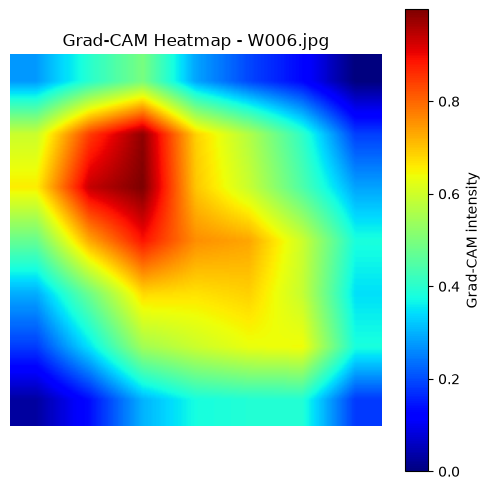

In [10]:
# Resize the 7x7 heatmap to 224x224
heatmap = torch.nn.functional.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

# Convert the heatmap into a NumPy array
heatmap = heatmap.squeeze().detach().cpu().numpy()

# Display the heatmap
plt.figure(figsize=(6, 6))
plt.imshow(heatmap, cmap="jet")
plt.colorbar(label="Grad-CAM intensity")
plt.title(f"Grad-CAM Heatmap - {sample_filename}")
plt.axis("off")
plt.show()

Overlay Grad-CAM on the fabric image

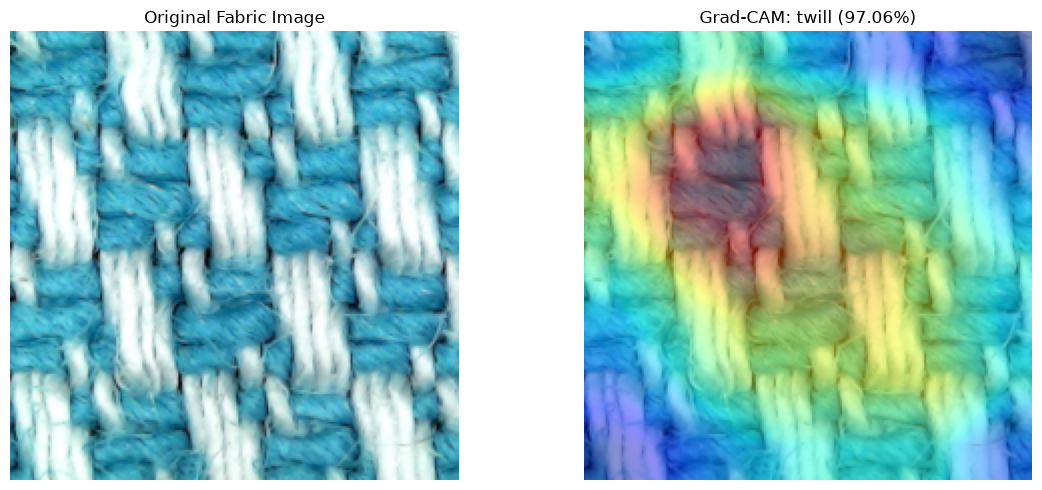

In [11]:
# Prepare the original processed image for display
display_image = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((224, 224))
])(original_image)

# Convert the image to a NumPy array
display_image = np.array(display_image)

# Display original image and Grad-CAM overlay
plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(display_image)
plt.title("Original Fabric Image")
plt.axis("off")

# Grad-CAM overlay
plt.subplot(1, 2, 2)
plt.imshow(display_image)
plt.imshow(heatmap, cmap="jet", alpha=0.45)
plt.title(f"Grad-CAM: {predicted_class} ({confidence:.2%})")
plt.axis("off")

plt.tight_layout()
plt.show()

Save the first Grad-CAM result

In [12]:
# Create a folder for Fold 1 explanations
fold_output_dir = EXPLANATION_DIR / "fold1"
fold_output_dir.mkdir(parents=True, exist_ok=True)

# Save the original image with its Grad-CAM overlay
output_path = fold_output_dir / f"{sample_filename.replace('.jpg', '_gradcam.png')}"

plt.figure(figsize=(6, 6))
plt.imshow(display_image)
plt.imshow(heatmap, cmap="jet", alpha=0.45)
plt.title(f"Grad-CAM: {predicted_class} ({confidence:.2%})")
plt.axis("off")
plt.tight_layout()

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.close()

print("Grad-CAM explanation saved:", output_path)
print("File exists:", output_path.exists())

Grad-CAM explanation saved: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\explanations\gradcam\fold1\W006_gradcam.png
File exists: True


Create a reusable Grad-CAM function

In [13]:
def generate_gradcam(model, input_tensor, target_layer):

    # Containers for activations and gradients
    captured = {
        "activations": None,
        "gradients": None
    }

    # Capture feature maps during the forward pass
    def forward_hook(module, input, output):
        captured["activations"] = output

    # Capture gradients during the backward pass
    def backward_hook(module, grad_input, grad_output):
        captured["gradients"] = grad_output[0]

    # Register hooks
    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)

    try:
        # Clear previous gradients
        model.zero_grad()

        # Forward pass
        outputs = model(input_tensor)

        # Convert outputs into probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Select the predicted class
        predicted_index = torch.argmax(probabilities, dim=1).item()

        # Get the predicted class score
        target_score = outputs[0, predicted_index]

        # Backward pass
        target_score.backward()

        # Retrieve activations and gradients
        feature_maps = captured["activations"]
        gradient_values = captured["gradients"]

        # Calculate importance weights
        weights = gradient_values.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Combine feature maps
        cam = (weights * feature_maps).sum(dim=1, keepdim=True)

        # Keep positive contributions
        cam = torch.relu(cam)

        # Resize heatmap to 224x224
        cam = torch.nn.functional.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        # Normalize heatmap
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        # Convert heatmap to NumPy
        heatmap = cam.squeeze().detach().cpu().numpy()

        return {
            "predicted_index": predicted_index,
            "probabilities": probabilities.detach().cpu().numpy()[0],
            "heatmap": heatmap
        }

    finally:
        # Remove hooks after generating the explanation
        forward_handle.remove()
        backward_handle.remove()

Test the reusable function

In [14]:
# Generate Grad-CAM explanation
gradcam_result = generate_gradcam(
    model,
    input_tensor,
    target_layer
)

# Extract results
new_heatmap = gradcam_result["heatmap"]
new_predicted_index = gradcam_result["predicted_index"]
new_confidence = gradcam_result["probabilities"][new_predicted_index]

print("Image:", sample_filename)
print("Actual class:", sample_actual_class)
print("Predicted class:", class_names[new_predicted_index])
print("Confidence:", round(float(new_confidence), 4))
print("Heatmap shape:", new_heatmap.shape)

Image: W006.jpg
Actual class: twill
Predicted class: twill
Confidence: 0.9706
Heatmap shape: (224, 224)


Test another image

In [15]:
# Select the second image from Fold 1
sample2_filename = fold1_images.iloc[1]["image_filename"]
sample2_actual_class = fold1_images.iloc[1]["Texture"]

# Load the image
sample2_path = IMAGE_DIR / sample2_filename
sample2_image = Image.open(sample2_path).convert("RGB")

# Apply the same preprocessing
sample2_tensor = preprocess(sample2_image).unsqueeze(0).to(device)

# Generate Grad-CAM
sample2_result = generate_gradcam(
    model,
    sample2_tensor,
    target_layer
)

# Extract prediction information
sample2_predicted_index = sample2_result["predicted_index"]
sample2_predicted_class = class_names[sample2_predicted_index]
sample2_confidence = sample2_result["probabilities"][sample2_predicted_index]

print("Image:", sample2_filename)
print("Actual class:", sample2_actual_class)
print("Predicted class:", sample2_predicted_class)
print("Confidence:", round(float(sample2_confidence), 4))
print("Heatmap shape:", sample2_result["heatmap"].shape)

Image: W007.jpg
Actual class: twill
Predicted class: twill
Confidence: 0.6982
Heatmap shape: (224, 224)


Visualise W007's explanation

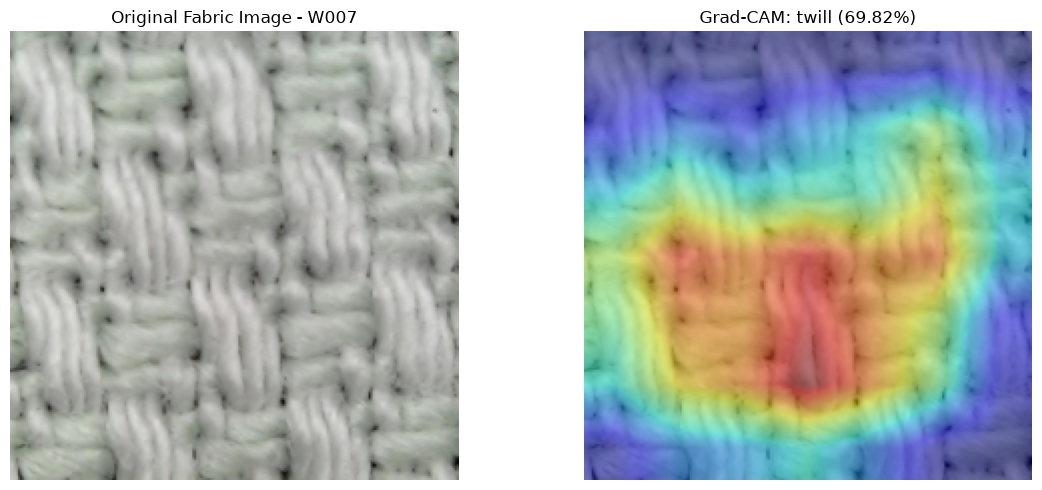

In [16]:
# Prepare W007 for visualisation
sample2_display = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((224, 224))
])(sample2_image)

sample2_display = np.array(sample2_display)

# Display original image and Grad-CAM overlay
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample2_display)
plt.title("Original Fabric Image - W007")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample2_display)
plt.imshow(sample2_result["heatmap"], cmap="jet", alpha=0.45)
plt.title(
    f"Grad-CAM: {sample2_predicted_class} "
    f"({sample2_confidence:.2%})"
)
plt.axis("off")

plt.tight_layout()
plt.show()

Prepare to load all five models

In [17]:
# Function to load the trained model for a particular fold

def load_fold_model(fold_number):

    # Locate the checkpoint for the requested fold
    checkpoint_path = MODEL_DIR / f"resnet18_fold{fold_number}.pth"

    # Check whether the checkpoint exists
    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Model checkpoint not found: {checkpoint_path}"
        )

    # Recreate the ResNet-18 architecture
    fold_model = models.resnet18(weights=None)

    # Configure the final layer for three fabric classes
    fold_model.fc = nn.Linear(
        fold_model.fc.in_features,
        len(class_names)
    )

    # Load the trained model parameters
    state_dict = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    fold_model.load_state_dict(state_dict)

    # Move model to the selected device
    fold_model = fold_model.to(device)

    # Set evaluation mode
    fold_model.eval()

    # Select the Grad-CAM target layer
    target_layer = fold_model.layer4[-1].conv2

    return fold_model, target_layer


# Check all five model checkpoints
for fold_number in range(1, 6):

    fold_model, fold_target_layer = load_fold_model(fold_number)

    print(f"Fold {fold_number}: Model loaded successfully")

Fold 1: Model loaded successfully
Fold 2: Model loaded successfully
Fold 3: Model loaded successfully
Fold 4: Model loaded successfully
Fold 5: Model loaded successfully


Generate Grad-CAM for all 27 Fold 1 test images

In [18]:
# Select Fold 1
fold_number = 1

# Load the correct Fold 1 model
fold_model, fold_target_layer = load_fold_model(fold_number)

# Select its 27 test images
fold_data = folds_df[
    folds_df["test_fold"] == fold_number
].copy()

# Prepare output folder
fold_output_dir = EXPLANATION_DIR / f"fold{fold_number}"
fold_output_dir.mkdir(parents=True, exist_ok=True)

# Access the original predictions from Notebook 03
prediction_lookup = predictions_df.set_index("image_filename")

# Store the results
fold_results = []

# Process each test image
for _, row in fold_data.iterrows():

    filename = row["image_filename"]
    actual_class = str(row["Texture"]).strip().lower()

    # Load image
    image_path = IMAGE_DIR / filename
    image = Image.open(image_path).convert("RGB")

    # Apply the original model preprocessing
    input_tensor = preprocess(image).unsqueeze(0).to(device)

    # Generate Grad-CAM
    result = generate_gradcam(
        fold_model,
        input_tensor,
        fold_target_layer
    )

    # Extract prediction
    predicted_index = result["predicted_index"]
    predicted_class = class_names[predicted_index]
    confidence = float(
        result["probabilities"][predicted_index]
    )

    # Check agreement with Notebook 03
    expected_prediction = str(
        prediction_lookup.loc[filename, "predicted_class"]
    ).strip().lower()

    prediction_matches = (
        predicted_class == expected_prediction
    )

    # Save numerical heatmap
    heatmap = result["heatmap"]

    heatmap_path = fold_output_dir / f"{Path(filename).stem}_heatmap.npy"
    np.save(heatmap_path, heatmap)

    # Prepare image for visualisation
    display_image = transforms.Compose([
        transforms.CenterCrop(480),
        transforms.Resize((224, 224))
    ])(image)

    display_image = np.array(display_image)

    # Save Grad-CAM overlay
    overlay_path = fold_output_dir / f"{Path(filename).stem}_gradcam.png"

    plt.figure(figsize=(5, 5))
    plt.imshow(display_image)
    plt.imshow(heatmap, cmap="jet", alpha=0.45)
    plt.title(f"{predicted_class} ({confidence:.2%})")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(overlay_path, dpi=150, bbox_inches="tight")
    plt.close()

    # Record results
    fold_results.append({
        "image_filename": filename,
        "fold": fold_number,
        "actual_class": actual_class,
        "predicted_class": predicted_class,
        "confidence": confidence,
        "correct": actual_class == predicted_class,
        "prediction_matches_notebook03": prediction_matches,
        "heatmap_path": str(heatmap_path),
        "overlay_path": str(overlay_path)
    })

    print(f"Processed: {filename}")

# Create results DataFrame
fold1_gradcam_df = pd.DataFrame(fold_results)

# Save Fold 1 results
fold1_csv_path = fold_output_dir / "fold1_gradcam_results.csv"
fold1_gradcam_df.to_csv(fold1_csv_path, index=False)

print("\nFold 1 Grad-CAM processing completed.")
print("Total images processed:", len(fold1_gradcam_df))
print("Correct predictions:", fold1_gradcam_df["correct"].sum())
print(
    "Predictions matching Notebook 03:",
    fold1_gradcam_df["prediction_matches_notebook03"].sum()
)
print("Results CSV exists:", fold1_csv_path.exists())

Processed: W006.jpg
Processed: W007.jpg
Processed: W008.jpg
Processed: W009.jpg
Processed: W010.jpg
Processed: W011.jpg
Processed: W047.jpg
Processed: W048.jpg
Processed: W049.jpg
Processed: W050.jpg
Processed: W051.jpg
Processed: W052.jpg
Processed: W053.jpg
Processed: W054.jpg
Processed: W055.jpg
Processed: W056.jpg
Processed: W067.jpg
Processed: W068.jpg
Processed: W069.jpg
Processed: W070.jpg
Processed: W071.jpg
Processed: W113.jpg
Processed: W118.jpg
Processed: W119.jpg
Processed: W120.jpg
Processed: W121.jpg
Processed: W122.jpg

Fold 1 Grad-CAM processing completed.
Total images processed: 27
Correct predictions: 16
Predictions matching Notebook 03: 27
Results CSV exists: True


Process the remaining four folds

In [19]:

# Process the remaining folds: 2, 3, 4 and 5

for fold_number in range(2, 6):

    print(f"\n========== Processing Fold {fold_number} ==========")

    # Load the correct model for this fold
    fold_model, fold_target_layer = load_fold_model(fold_number)

    # Select this fold's test images
    fold_data = folds_df[
        folds_df["test_fold"] == fold_number
    ].copy()

    # Create output folder
    fold_output_dir = EXPLANATION_DIR / f"fold{fold_number}"
    fold_output_dir.mkdir(parents=True, exist_ok=True)

    fold_results = []

    # Process each test image
    for _, row in fold_data.iterrows():

        filename = row["image_filename"]
        actual_class = str(row["Texture"]).strip().lower()

        # Load image
        image_path = IMAGE_DIR / filename
        image = Image.open(image_path).convert("RGB")

        # Apply training preprocessing
        input_tensor = preprocess(image).unsqueeze(0).to(device)

        # Generate Grad-CAM
        result = generate_gradcam(
            fold_model,
            input_tensor,
            fold_target_layer
        )

        # Get prediction
        predicted_index = result["predicted_index"]
        predicted_class = class_names[predicted_index]

        confidence = float(
            result["probabilities"][predicted_index]
        )

        # Compare against Notebook 03 prediction
        expected_prediction = str(
            prediction_lookup.loc[filename, "predicted_class"]
        ).strip().lower()

        prediction_matches = (
            predicted_class == expected_prediction
        )

        # Save numerical heatmap
        heatmap = result["heatmap"]

        heatmap_path = (
            fold_output_dir /
            f"{Path(filename).stem}_heatmap.npy"
        )

        np.save(heatmap_path, heatmap)

        # Prepare original image for visualisation
        display_image = transforms.Compose([
            transforms.CenterCrop(480),
            transforms.Resize((224, 224))
        ])(image)

        display_image = np.array(display_image)

        # Save Grad-CAM overlay
        overlay_path = (
            fold_output_dir /
            f"{Path(filename).stem}_gradcam.png"
        )

        plt.figure(figsize=(5, 5))
        plt.imshow(display_image)
        plt.imshow(heatmap, cmap="jet", alpha=0.45)
        plt.title(f"{predicted_class} ({confidence:.2%})")
        plt.axis("off")
        plt.tight_layout()

        plt.savefig(
            overlay_path,
            dpi=150,
            bbox_inches="tight"
        )

        plt.close()

        # Record the explanation results
        fold_results.append({
            "image_filename": filename,
            "fold": fold_number,
            "actual_class": actual_class,
            "predicted_class": predicted_class,
            "confidence": confidence,
            "correct": actual_class == predicted_class,
            "prediction_matches_notebook03": prediction_matches,
            "heatmap_path": str(heatmap_path),
            "overlay_path": str(overlay_path)
        })

    # Create results DataFrame
    fold_gradcam_df = pd.DataFrame(fold_results)

    # Save this fold's results
    fold_csv_path = (
        fold_output_dir /
        f"fold{fold_number}_gradcam_results.csv"
    )

    fold_gradcam_df.to_csv(fold_csv_path, index=False)

    # Display fold summary
    print("Images processed:", len(fold_gradcam_df))
    print("Correct predictions:", fold_gradcam_df["correct"].sum())

    print(
        "Predictions matching Notebook 03:",
        fold_gradcam_df["prediction_matches_notebook03"].sum()
    )

    print("Results CSV saved:", fold_csv_path.exists())


print("\nAll remaining folds processed!")



========== Processing Fold 2 ==========
Images processed: 23
Correct predictions: 20
Predictions matching Notebook 03: 23
Results CSV saved: True

========== Processing Fold 3 ==========
Images processed: 30
Correct predictions: 23
Predictions matching Notebook 03: 30
Results CSV saved: True

========== Processing Fold 4 ==========
Images processed: 26
Correct predictions: 25
Predictions matching Notebook 03: 26
Results CSV saved: True

========== Processing Fold 5 ==========
Images processed: 24
Correct predictions: 18
Predictions matching Notebook 03: 24
Results CSV saved: True

All remaining folds processed!


Combine and verify all 130 explanations

In [20]:
# Load the five fold-specific Grad-CAM result files
all_gradcam_results = []

for fold_number in range(1, 6):

    csv_path = (
        EXPLANATION_DIR /
        f"fold{fold_number}" /
        f"fold{fold_number}_gradcam_results.csv"
    )

    fold_df = pd.read_csv(csv_path)
    all_gradcam_results.append(fold_df)

# Combine all five folds
gradcam_results_df = pd.concat(
    all_gradcam_results,
    ignore_index=True
)

# Save the complete Grad-CAM results
combined_csv_path = EXPLANATION_DIR / "gradcam_results.csv"

gradcam_results_df.to_csv(
    combined_csv_path,
    index=False
)

# Verify the results
print("Total explanations:", len(gradcam_results_df))

print(
    "Unique images:",
    gradcam_results_df["image_filename"].nunique()
)

print(
    "Predictions matching Notebook 03:",
    gradcam_results_df["prediction_matches_notebook03"].sum()
)

print(
    "Correct predictions:",
    gradcam_results_df["correct"].sum()
)

print("\nImages processed per fold:")
print(gradcam_results_df["fold"].value_counts().sort_index())

print("\nGrad-CAM results saved:", combined_csv_path.exists())

Total explanations: 130
Unique images: 130
Predictions matching Notebook 03: 130
Correct predictions: 102

Images processed per fold:
fold
1    27
2    23
3    30
4    26
5    24
Name: count, dtype: int64

Grad-CAM results saved: True


Verify all saved Grad-CAM files

In [21]:
# Verify all saved Grad-CAM files

missing_heatmaps = []
missing_overlays = []
incorrect_shapes = []

for _, row in gradcam_results_df.iterrows():

    heatmap_path = Path(row["heatmap_path"])
    overlay_path = Path(row["overlay_path"])

    # Check numerical heatmap
    if not heatmap_path.exists():
        missing_heatmaps.append(str(heatmap_path))
    else:
        heatmap_array = np.load(heatmap_path)

        if heatmap_array.shape != (224, 224):
            incorrect_shapes.append(str(heatmap_path))

    # Check visual explanation
    if not overlay_path.exists():
        missing_overlays.append(str(overlay_path))


print("Total explanations:", len(gradcam_results_df))
print("Missing numerical heatmaps:", len(missing_heatmaps))
print("Missing visual overlays:", len(missing_overlays))
print("Incorrect heatmap dimensions:", len(incorrect_shapes))

print("\nGrad-CAM verification:")
print("All heatmaps saved:", len(missing_heatmaps) == 0)
print("All overlays saved:", len(missing_overlays) == 0)
print("All heatmaps have correct dimensions:", len(incorrect_shapes) == 0)

Total explanations: 130
Missing numerical heatmaps: 0
Missing visual overlays: 0
Incorrect heatmap dimensions: 0

Grad-CAM verification:
All heatmaps saved: True
All overlays saved: True
All heatmaps have correct dimensions: True
